# Thực nghiệm thử tham số 4 mô hình trên tập A


Thử thay đổi một siêu tham số ở mỗi mô hình Logistic Regression, Random Forest, SVM và XGBoost trên tập A (36 đặc trưng). Các mô hình được đánh giá bằng Stratified 5-fold CV và chỉ số Macro-F1. Kết quả được đối chiếu với cấu hình mốc của nhóm trên cùng tập A; không sử dụng tập test.

## 1. Thiết lập tham số

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Tìm thư mục gốc của dự án, dù VS Code mở notebook từ thư mục con.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "ML01_Student_Dropout"]
project_dir = next((p for p in candidates if (p / "feature_b" / "common.py").is_file()), None)
if project_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy ML01_Student_Dropout/feature_b/common.py. "
        "Hãy mở thư mục dự án ML01_Student_Dropout trong VS Code."
    )

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = project_dir / "experiments" / "2026-11-16_ThuThamSo_4MoHinh_A_Ly"
N_FOLDS = 5
SEED = 42

# So với cấu hình mốc tập A: mỗi mô hình chỉ đổi một tham số.
configs = {
    "Logistic Regression": (
        LogisticRegression,
        {"C": 0.3, "class_weight": "balanced", "solver": "lbfgs", "max_iter": 3000},
        True,
    ),
    "Random Forest": (
        RandomForestClassifier,
        {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 2,
         "class_weight": "balanced", "random_state": SEED, "n_jobs": 1},
        False,
    ),
    "SVM": (
        SVC,
        {"kernel": "rbf", "C": 10, "gamma": 0.02, "class_weight": "balanced"},
        True,
    ),
    "XGBoost": (
        XGBClassifier,
        {"n_estimators": 150, "max_depth": 6, "learning_rate": 0.05,
         "objective": "multi:softprob", "num_class": 3, "eval_metric": "mlogloss",
         "tree_method": "hist", "random_state": SEED, "n_jobs": 1},
        False,
    ),
}

changed_params = {
    "Logistic Regression": ("C", "0.1", "0.3"),
    "Random Forest": ("min_samples_leaf", "1", "2"),
    "SVM": ("gamma", "0.01", "0.02"),
    "XGBoost": ("learning_rate", "0.1", "0.05"),
}
config_table = pd.DataFrame([
    {
        "Mô hình": name,
        "Tham số đổi": changed_params[name][0],
        "Giá trị mốc": changed_params[name][1],
        "Giá trị thử": changed_params[name][2],
        "Cấu hình thử": ", ".join(f"{k}={v!r}" for k, v in params.items()),
    }
    for name, (_, params, _) in configs.items()
])
display(config_table)

,Mô hình,Tham số đổi,Giá trị mốc,Giá trị thử,Cấu hình thử
0,Logistic Regression,C,0.1,0.3,"C=0.3, class_weight='balanced', solver='lbfgs'..."
1,Random Forest,min_samples_leaf,1,2,"n_estimators=200, max_depth=None, min_samples_..."
2,SVM,gamma,0.01,0.02,"kernel='rbf', C=10, gamma=0.02, class_weight='..."
3,XGBoost,learning_rate,0.1,0.05,"n_estimators=150, max_depth=6, learning_rate=0..."


## 2. Huấn luyện và đánh giá bốn mô hình

Dùng cùng 5 fold phân tầng (seed 42) trên `development.csv` và chỉ sử dụng 36 đặc trưng thuộc tập A.

In [2]:
X_a, X_ab, y = load_development(data_path)
assert X_a.shape[1] == 36, "Tập A phải có 36 đặc trưng."
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows, fold_tables = [], []
for name, (model_class, params, scale_numeric) in configs.items():
    print(f"Đang chạy {name} trên tập A...")
    model = model_class(**params)
    summary, fold_scores = evaluate(name, model, scale_numeric, "A", X_a, y, folds)
    summary_rows.append(summary)
    fold_tables.append(fold_scores)

results = pd.DataFrame(summary_rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
fold_results = pd.concat(fold_tables, ignore_index=True)
display(results.round(6))
print(f"Cao nhất ở lượt thử: {results.iloc[0]['model']} ({results.iloc[0]['cv_macro_f1']:.6f})")

3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang chạy Logistic Regression trên tập A...
Đang chạy Random Forest trên tập A...
Đang chạy SVM trên tập A...
Đang chạy XGBoost trên tập A...


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate
0,Logistic Regression,A,36,0.715517,0.737907,0.607874,0.822864
1,Random Forest,A,36,0.714528,0.749340,0.464567,0.903792
2,XGBoost,A,36,0.708949,0.762533,0.409449,0.924731
3,SVM,A,36,0.700946,0.741425,0.525984,0.840407


Cao nhất ở lượt thử: Logistic Regression (0.715517)


## 3. So sánh và lưu kết quả

So sánh điểm CV Macro-F1 mới với cấu hình mốc trên tập A từ `experiments/feature_b/*_a_vs_ab.csv`. Các file Excel, CSV và biểu đồ sẽ lưu trong folder thực nghiệm riêng ngày 16/11.

,Mô hình,Tham số thay đổi,Giá trị mốc,Giá trị thử,CV Macro-F1 mốc A,CV Macro-F1 thử A,Chênh lệch (thử - mốc)
0,Logistic Regression,C,0.1,0.3,0.717353,0.715517,-0.001837
1,Random Forest,min_samples_leaf,1,2,0.716244,0.714528,-0.001716
2,SVM,gamma,0.01,0.02,0.715364,0.700946,-0.014418
3,XGBoost,learning_rate,0.1,0.05,0.713649,0.708949,-0.004701


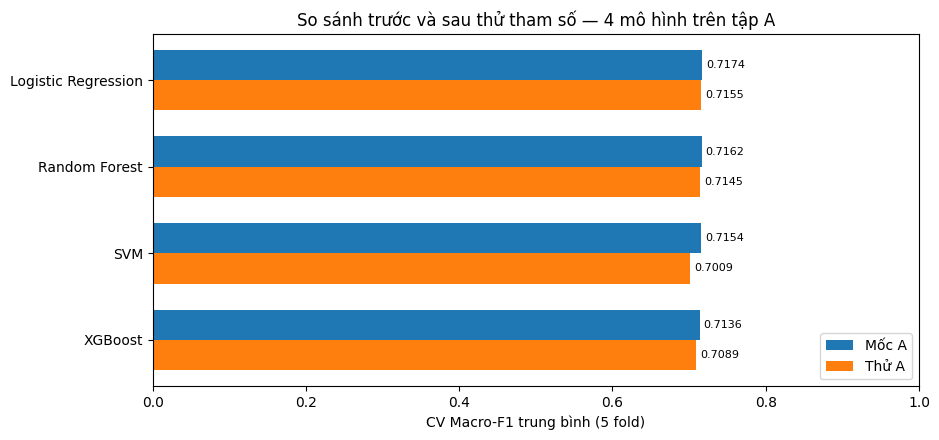

Đã lưu vào: C:\doan\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-16_ThuThamSo_4MoHinh_A_Ly
 - ket_qua.xlsx
 - ket_qua_tong_hop.csv
 - diem_tung_fold.csv
 - so_sanh_macro_f1.png


In [3]:
model_codes = {
    "Logistic Regression": "lr",
    "Random Forest": "rf",
    "SVM": "svm",
    "XGBoost": "xgb",
}
new_scores = results.set_index("model")["cv_macro_f1"]
comparison_rows = []
for name, code in model_codes.items():
    baseline_path = project_dir / "experiments" / "feature_b" / f"{code}_a_vs_ab.csv"
    if not baseline_path.exists():
        raise FileNotFoundError(f"Thiếu file mốc: {baseline_path}")
    baseline = pd.read_csv(baseline_path)
    scores_a = baseline.loc[baseline["data"].eq("A"), "cv_macro_f1"]
    if len(scores_a) != 1:
        raise ValueError(f"Không tìm được đúng 1 dòng tập A trong {baseline_path.name}")
    old_score, new_score = float(scores_a.iloc[0]), float(new_scores.loc[name])
    parameter, before, after = changed_params[name]
    comparison_rows.append({
        "Mô hình": name,
        "Tham số thay đổi": parameter,
        "Giá trị mốc": before,
        "Giá trị thử": after,
        "CV Macro-F1 mốc A": old_score,
        "CV Macro-F1 thử A": new_score,
        "Chênh lệch (thử - mốc)": new_score - old_score,
    })
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(6))

output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "ket_qua.xlsx"
summary_path = output_dir / "ket_qua_tong_hop.csv"
fold_path = output_dir / "diem_tung_fold.csv"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Người chạy": "Ly",
    "Ngày": "16/11/2026",
    "Tập đặc trưng": "A",
    "Dữ liệu": "data/processed/development.csv",
    "Số mẫu": len(y),
    "Số đặc trưng": X_a.shape[1],
    "Kiểm định chéo": "StratifiedKFold",
    "Số fold": N_FOLDS,
    "Shuffle": True,
    "Random state": SEED,
    "Chỉ số": "CV Macro-F1 trung bình",
}])

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    comparison.to_excel(writer, sheet_name="So sanh voi moc", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    run_info.to_excel(writer, sheet_name="Thong tin", index=False)
results.to_csv(summary_path, index=False)
fold_results.to_csv(fold_path, index=False)

fig, ax = plt.subplots(figsize=(9.5, 4.5))
y_pos = range(len(comparison))
width = 0.35
bars1 = ax.barh([p - width/2 for p in y_pos], comparison["CV Macro-F1 mốc A"], height=width, label="Mốc A")
bars2 = ax.barh([p + width/2 for p in y_pos], comparison["CV Macro-F1 thử A"], height=width, label="Thử A")
ax.set_yticks(list(y_pos), comparison["Mô hình"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung bình (5 fold)")
ax.set_title("So sánh trước và sau thử tham số — 4 mô hình trên tập A")
ax.bar_label(bars1, fmt="%.4f", padding=3, fontsize=8)
ax.bar_label(bars2, fmt="%.4f", padding=3, fontsize=8)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(image_path, dpi=180, bbox_inches="tight")
plt.show()

print("Đã lưu vào:", output_dir.resolve())
for p in (excel_path, summary_path, fold_path, image_path):
    print(" -", p.name)

## 4. Nhận xét

Sau khi chạy, so sánh cột **Chênh lệch (thử - mốc)** để nhận xét mô hình nào tăng hoặc giảm CV Macro-F1. Chưa đánh giá trên tập test.